<a href="https://colab.research.google.com/github/Tensor-Reloaded/Neural-Networks-2026/blob/main/Lab06/Lab06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 06: Overfitting, Activations, and Regularization

This lab studies several ideas that directly affect how a neural network learns and generalizes:

- how overfitting appears in the training and validation curves;
- how activation functions shape signals and gradients;
- how L1 and L2 penalties constrain model parameters;
- how dropout introduces noise during training;
- how batch normalization and layer normalization differ;
- how simple image augmentations create useful variations of an input.

The implementations use arrays and elementary numerical operations. The goal is to make every transformation visible rather than hide it behind pre-built components.


In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
plt.rcParams["figure.figsize"] = (7, 4)


## 1. Overfitting on a simple regression problem

We generate noisy samples from


$y = \sin(2x).$

The samples are shuffled and divided equally: **50% for training and 50% for validation**. The validation samples are never used to update the model. They provide an estimate of how well the learned function transfers to unseen points.

We compare a small network with a much larger one. The larger network has enough capacity to reproduce fine details in the training data, including noise. Overfitting becomes visible when its training error continues to decrease while its validation error stops improving or begins to increase.


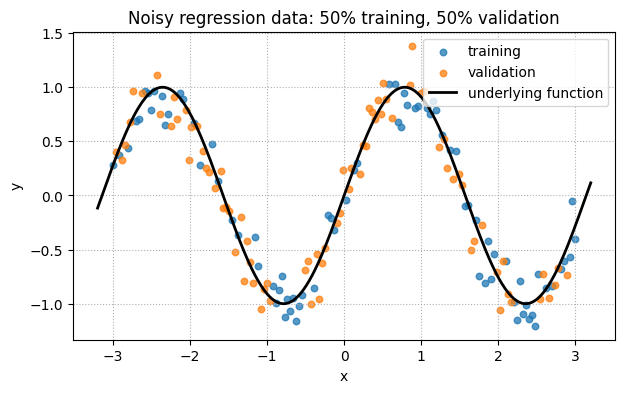

In [2]:
def make_regression(n=160, noise=0.18, seed=7):
    rng = np.random.default_rng(seed)
    x = np.linspace(-3.0, 3.0, n, dtype=np.float64)[:, None]
    y_clean = np.sin(2.0 * x)
    y = y_clean + noise * rng.standard_normal(y_clean.shape)

    order = rng.permutation(n)
    split = n // 2
    train_idx = order[:split]
    val_idx = order[split:]
    return x[train_idx], y[train_idx], x[val_idx], y[val_idx]

x_train, y_train, x_val, y_val = make_regression()
x_plot = np.linspace(-3.2, 3.2, 500)[:, None]

plt.scatter(x_train, y_train, s=22, alpha=0.75, label="training")
plt.scatter(x_val, y_val, s=22, alpha=0.75, label="validation")
plt.plot(x_plot, np.sin(2 * x_plot), color="black", linewidth=2, label="underlying function")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Noisy regression data: 50% training, 50% validation")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()


### A small neural network written with arrays

Each dense layer computes

$\mathbf{z}=\mathbf{x}\mathbf{W}+\mathbf{b}.$

Hidden layers then apply an activation function. During the backward pass, the model stores the derivatives of the loss with respect to every weight and bias. A compact parameter update routine is used only to train the examples in this notebook; optimization methods are not the subject of this lab.


In [3]:
device = torch.device("cpu")


class MLP(nn.Module):
    def __init__(self, dimensions, seed=0):
        super().__init__()

        torch.manual_seed(seed)

        self.layers = nn.ModuleList(
            nn.Linear(fan_in, fan_out) for fan_in, fan_out in zip(dimensions[:-1], dimensions[1:])
        )

        for layer in self.layers:
            nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu")
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = torch.relu(layer(x))

        return self.layers[-1](x)

    @torch.inference_mode()
    def predict(self, x):
        x = torch.as_tensor(x, dtype=torch.float32, device=device)
        self.eval()
        return self(x)


def mse(prediction, target):
    return torch.mean((prediction - target) ** 2)


def train(model, x_train, y_train, x_val, y_val, epochs=2000, lr=1e-3, l1=0.0, l2=0.0):
    model = model.to(device)

    x_train = torch.as_tensor(x_train, dtype=torch.float32, device=device)
    y_train = torch.as_tensor(y_train, dtype=torch.float32, device=device)
    x_val = torch.as_tensor(x_val, dtype=torch.float32, device=device)
    y_val = torch.as_tensor(y_val, dtype=torch.float32, device=device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train": [],
        "validation": [],
        "l1_norm": [],
        "l2_norm": [],
    }

    for _ in range(epochs):
        model.train()

        optimizer.zero_grad()

        prediction = model(x_train)
        loss = mse(prediction, y_train)

        weights = [layer.weight for layer in model.layers]

        if l1 > 0.0:
            loss = loss + l1 * sum(weight.abs().sum() for weight in weights)

        if l2 > 0.0:
            loss = loss + l2 * sum(weight.square().sum() for weight in weights)

        loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():
            train_loss = mse(model(x_train), y_train).item()
            validation_loss = mse(model(x_val), y_val).item()

            l1_norm = sum(weight.abs().sum() for weight in weights).item()

            l2_norm = torch.sqrt(sum(weight.square().sum() for weight in weights)).item()

        history["train"].append(train_loss)
        history["validation"].append(validation_loss)
        history["l1_norm"].append(l1_norm)
        history["l2_norm"].append(l2_norm)

    return history

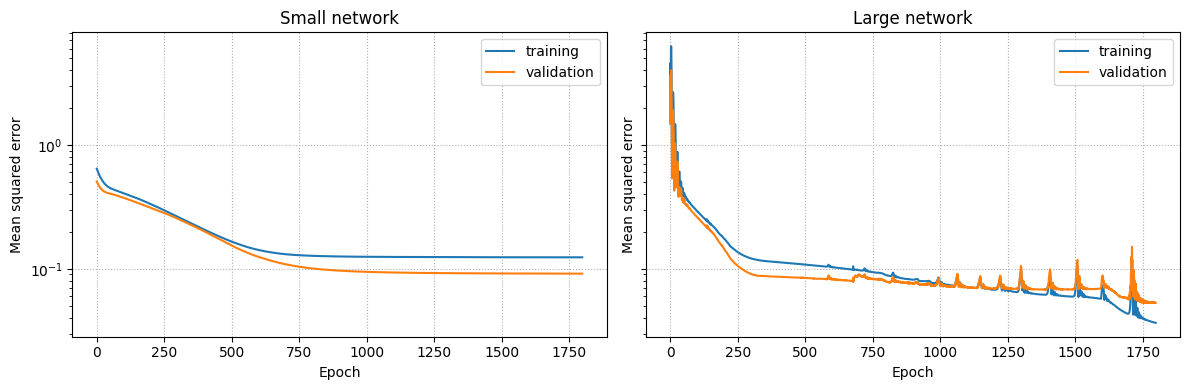

In [4]:
small_model = MLP([1, 12, 1], seed=1)
large_model = MLP([1, 256, 256, 1], seed=1)

small_history = train(small_model, x_train, y_train, x_val, y_val, epochs=1800, lr=1e-3)
large_history = train(large_model, x_train, y_train, x_val, y_val, epochs=1800, lr=1e-3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, history, title in [
    (axes[0], small_history, "Small network"),
    (axes[1], large_history, "Large network"),
]:
    ax.plot(history["train"], label="training")
    ax.plot(history["validation"], label="validation")
    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean squared error")
    ax.set_title(title)
    ax.grid(True, linestyle=":")
    ax.legend()
plt.tight_layout()
plt.show()


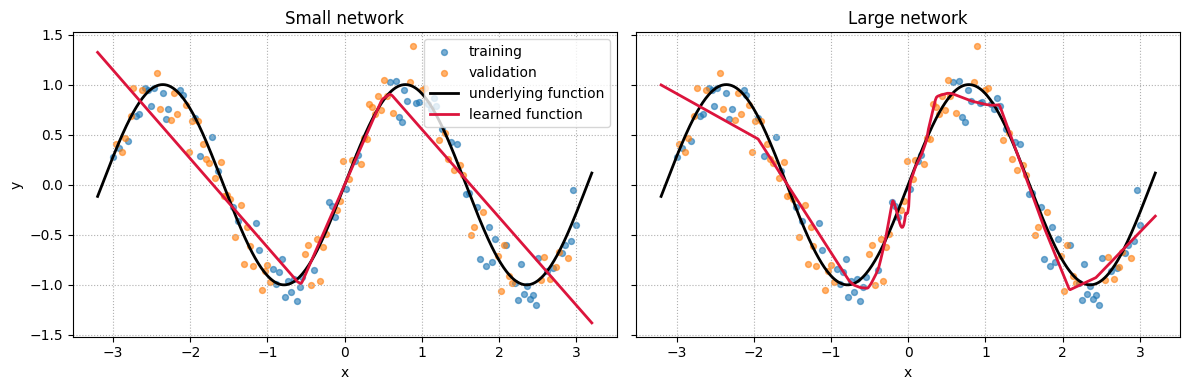

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, model, title in [
    (axes[0], small_model, "Small network"),
    (axes[1], large_model, "Large network"),
]:
    ax.scatter(x_train, y_train, s=18, alpha=0.6, label="training")
    ax.scatter(x_val, y_val, s=18, alpha=0.6, label="validation")
    ax.plot(x_plot, np.sin(2 * x_plot), color="black", linewidth=2, label="underlying function")
    ax.plot(x_plot, model.predict(x_plot), color="crimson", linewidth=2, label="learned function")
    ax.set_xlabel("x")
    ax.set_title(title)
    ax.grid(True, linestyle=":")
axes[0].set_ylabel("y")
axes[0].legend()
plt.tight_layout()
plt.show()


### Reading the result

A low training error is not enough to establish that a model learned the underlying relationship. The useful signal is the distance between training and validation behavior:

- **underfitting:** both errors remain high;
- **good fit:** both errors become low and remain close;
- **overfitting:** training error keeps falling while validation error stagnates or rises.

Model capacity is not harmful by itself. Overfitting appears when the available evidence and regularization are insufficient to constrain that capacity.


## 2. Activation functions

An activation function introduces non-linearity. Without it, stacking dense layers still produces only a linear transformation.

We compare three common choices:

- **Sigmoid** maps every value to \((0,1)\), but its derivative becomes very small for large positive or negative inputs.
- **ReLU** keeps positive values and replaces negative values with zero. It is simple and does not saturate on its positive side, but negative inputs receive zero gradient.
- **GELU** changes the signal smoothly. Small negative values are attenuated rather than removed abruptly.


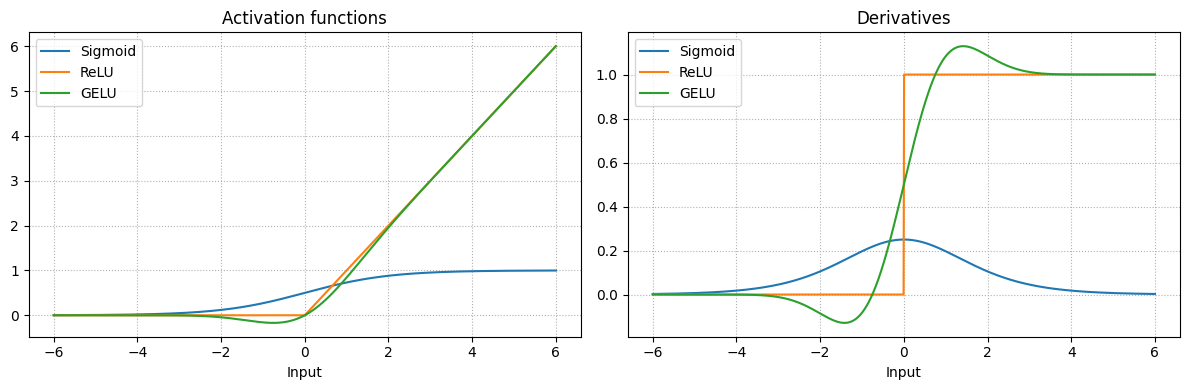

In [6]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def relu(x):
    return np.maximum(x, 0.0)


def relu_grad(x):
    return (x > 0.0).astype(x.dtype)


def sigmoid_derivative(x):
    y = sigmoid(x)
    return y * (1.0 - y)


def gelu(x):
    c = np.sqrt(2.0 / np.pi)
    return 0.5 * x * (1.0 + np.tanh(c * (x + 0.044715 * x**3)))


def gelu_derivative(x):
    c = np.sqrt(2.0 / np.pi)
    u = c * (x + 0.044715 * x**3)
    tanh_u = np.tanh(u)
    du = c * (1.0 + 3.0 * 0.044715 * x**2)
    return 0.5 * (1.0 + tanh_u) + 0.5 * x * (1.0 - tanh_u**2) * du


x = np.linspace(-6.0, 6.0, 1000)
functions = {
    "Sigmoid": (sigmoid(x), sigmoid_derivative(x)),
    "ReLU": (relu(x), relu_grad(x)),
    "GELU": (gelu(x), gelu_derivative(x)),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (values, derivatives) in functions.items():
    axes[0].plot(x, values, label=name)
    axes[1].plot(x, derivatives, label=name)
axes[0].set_title("Activation functions")
axes[1].set_title("Derivatives")
for ax in axes:
    ax.set_xlabel("Input")
    ax.grid(True, linestyle=":")
    ax.legend()
plt.tight_layout()
plt.show()


## 3. L1 and L2 regularization

A regularization penalty is added to the data-fitting loss during training.

L1 regularization uses

$\lambda_1\sum_i |w_i|.$

Its gradient has approximately constant magnitude away from zero. It therefore tends to push weak parameters all the way toward zero and can encourage sparse solutions.

L2 regularization uses

$\lambda_2\sum_i w_i^2.$

Its gradient is proportional to each parameter. Large values receive a stronger correction, so L2 tends to distribute information across many smaller weights rather than remove parameters entirely.

The next experiment tracks both parameter norms. The comparison is most useful when the regularization strengths are treated as tunable values rather than assumed to be directly equivalent.


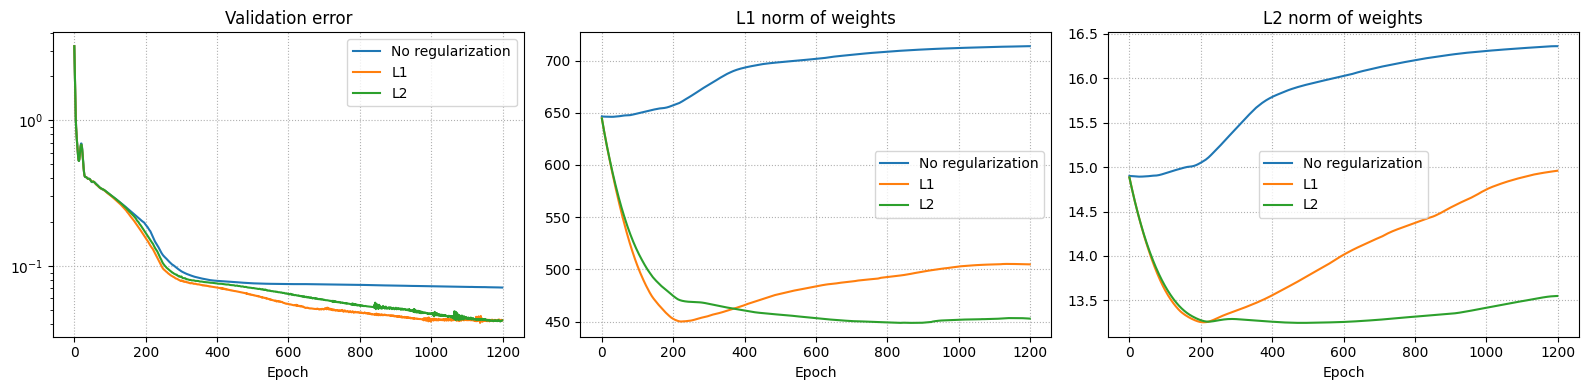

In [7]:
settings = [
    ("No regularization", 0.0, 0.0),
    ("L1", 2e-5, 0.0),
    ("L2", 0.0, 2e-4),
]
regularized_runs = {}

for label, l1_strength, l2_strength in settings:
    model = MLP([1, 64, 64, 1], seed=3)
    history = train(model, x_train, y_train, x_val, y_val, epochs=1200, lr=1e-3, l1=l1_strength, l2=l2_strength)
    regularized_runs[label] = (model, history)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for label, (_, history) in regularized_runs.items():
    axes[0].plot(history["validation"], label=label)
    axes[1].plot(history["l1_norm"], label=label)
    axes[2].plot(history["l2_norm"], label=label)
axes[0].set_title("Validation error")
axes[1].set_title("L1 norm of weights")
axes[2].set_title("L2 norm of weights")
axes[0].set_yscale("log")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True, linestyle=":")
    ax.legend()
plt.tight_layout()
plt.show()


## 4. Dropout

Dropout randomly removes part of a hidden representation during training. With removal probability \(p\), a binary mask is sampled independently for the activations. The values that remain are divided by \(1-p\), which keeps their expected scale unchanged:

\[
\widetilde{h}=\frac{m\odot h}{1-p},
\qquad m_i\sim\operatorname{Bernoulli}(1-p).
\]

At evaluation time, no values are removed. Dropout prevents the network from relying on the same set of hidden units for every example and every update.


In [8]:
def dropout(x, probability, training=True, rng=None):
    if not training or probability == 0.0:
        return x
    if not 0.0 <= probability < 1.0:
        raise ValueError("probability must be in [0, 1)")
    rng = np.random.default_rng() if rng is None else rng
    keep = rng.random(x.shape) >= probability
    return x * keep / (1.0 - probability)

rng = np.random.default_rng(5)
activations = np.ones((4, 12))
dropped = dropout(activations, probability=0.4, training=True, rng=rng)
evaluation = dropout(activations, probability=0.4, training=False, rng=rng)

print("Training-time output:", dropped)
print("Mean before dropout:", activations.mean())
print("Mean after inverted dropout:", dropped.mean())
print("Evaluation output is unchanged:", np.array_equal(activations, evaluation))


Training-time output: [[1.66666667 1.66666667 1.66666667 0.         0.         0.
  1.66666667 0.         0.         1.66666667 1.66666667 0.        ]
 [1.66666667 1.66666667 1.66666667 1.66666667 0.         1.66666667
  1.66666667 0.         1.66666667 0.         1.66666667 0.        ]
 [1.66666667 1.66666667 0.         1.66666667 1.66666667 0.
  1.66666667 0.         1.66666667 1.66666667 0.         0.        ]
 [1.66666667 0.         0.         1.66666667 1.66666667 1.66666667
  0.         0.         1.66666667 1.66666667 1.66666667 0.        ]]
Mean before dropout: 1.0
Mean after inverted dropout: 0.9722222222222223
Evaluation output is unchanged: True


## 5. Batch normalization and layer normalization

Both methods standardize activations, but they collect statistics along different axes.

### Batch normalization

For a matrix with shape \((N,F)\), batch normalization computes one mean and variance for each feature using the \(N\) samples in the current batch:

$\mu_f=\frac{1}{N}\sum_{n=1}^{N}x_{nf},
\qquad
\sigma_f^2=\frac{1}{N}\sum_{n=1}^{N}(x_{nf}-\mu_f)^2.$

Each feature column is normalized across samples. During evaluation, stored running statistics are used because the current batch may be small or may contain only one sample. Its behavior therefore depends on how representative and sufficiently large the training batches are.

### Layer normalization

Layer normalization computes one mean and variance for each sample using that sample's features:

$
\mu_n=\frac{1}{F}\sum_{f=1}^{F}x_{nf},
\qquad
\sigma_n^2=\frac{1}{F}\sum_{f=1}^{F}(x_{nf}-\mu_n)^2.
$

Each row is normalized independently. It uses the same computation during training and evaluation and does not depend on other samples in the batch.

Both methods normally include learnable scale and shift parameters. Here, they are shown explicitly as `gamma` and `beta`.


In [9]:
def batch_norm(x, gamma, beta, epsilon=1e-5):
    mean = x.mean(axis=0, keepdims=True)
    variance = x.var(axis=0, keepdims=True)
    normalized = (x - mean) / np.sqrt(variance + epsilon)
    return gamma * normalized + beta


def layer_norm(x, gamma, beta, epsilon=1e-5):
    mean = x.mean(axis=1, keepdims=True)
    variance = x.var(axis=1, keepdims=True)
    normalized = (x - mean) / np.sqrt(variance + epsilon)
    return gamma * normalized + beta


rng = np.random.default_rng(9)
x = rng.normal(loc=np.array([[-3.0, 0.0, 4.0, 10.0]]), scale=np.array([[0.5, 1.0, 2.0, 3.0]]), size=(256, 4))
gamma = np.ones((1, x.shape[1]))
beta = np.zeros((1, x.shape[1]))

x_batch = batch_norm(x, gamma, beta)
x_layer = layer_norm(x, gamma, beta)

print("Mean of each feature before normalization:", np.round(x.mean(axis=0), 3))
print("Mean of each feature after batch normalization:", np.round(x_batch.mean(axis=0), 3))
print("Mean of the first five samples after layer normalization:", np.round(x_layer.mean(axis=1)[:5], 3))
print("Variance of the first five samples after layer normalization:", np.round(x_layer.var(axis=1)[:5], 3))


Mean of each feature before normalization: [-2.975 -0.057  3.963 10.121]
Mean of each feature after batch normalization: [ 0.  0. -0.  0.]
Mean of the first five samples after layer normalization: [ 0. -0.  0.  0.  0.]
Variance of the first five samples after layer normalization: [1. 1. 1. 1. 1.]


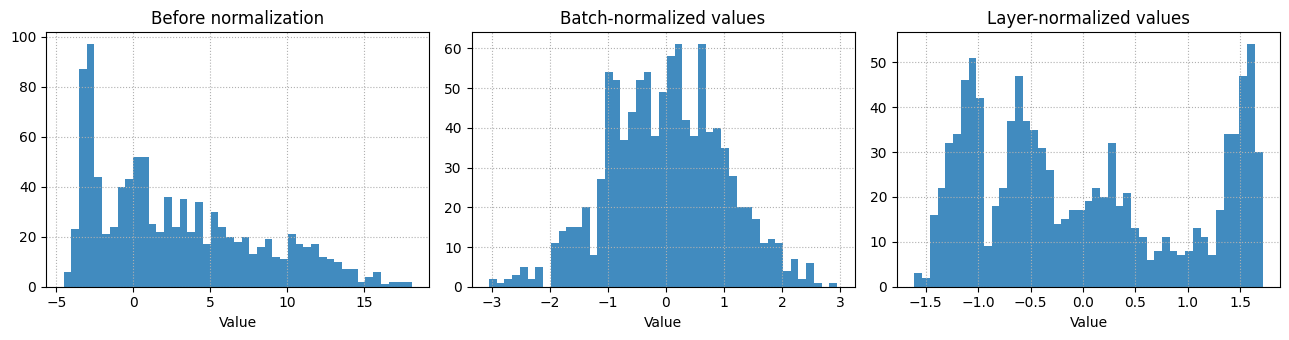

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(x.ravel(), bins=45, alpha=0.85)
axes[0].set_title("Before normalization")
axes[1].hist(x_batch.ravel(), bins=45, alpha=0.85)
axes[1].set_title("Batch-normalized values")
axes[2].hist(x_layer.ravel(), bins=45, alpha=0.85)
axes[2].set_title("Layer-normalized values")
for ax in axes:
    ax.set_xlabel("Value")
    ax.grid(True, linestyle=":")
plt.tight_layout()
plt.show()


## 6. Image augmentation with array operations

Data augmentation creates plausible variations of existing training examples. The label should remain valid after the transformation.

We demonstrate horizontal and vertical flips, a 90-degree rotation, additive noise, and random cropping.

### What cropping does

A crop selects a smaller rectangular region from the original image. If the selected region were simply displayed at its native size, the network would receive a smaller input. A common training transformation therefore selects the crop and resizes it back to the expected dimensions.

This changes both position and apparent scale. The model can no longer memorize that an object always appears at exactly the same coordinates, and it learns to use local visual evidence. Cropping is useful only when the selected region still contains enough information for the original label to remain correct.

The synthetic image below makes the transformation easy to inspect. White squares alternate with colored squares whose color changes from red on the left to blue on the right.


Crop box (top, left, height, width): (82, 106, 144, 144)


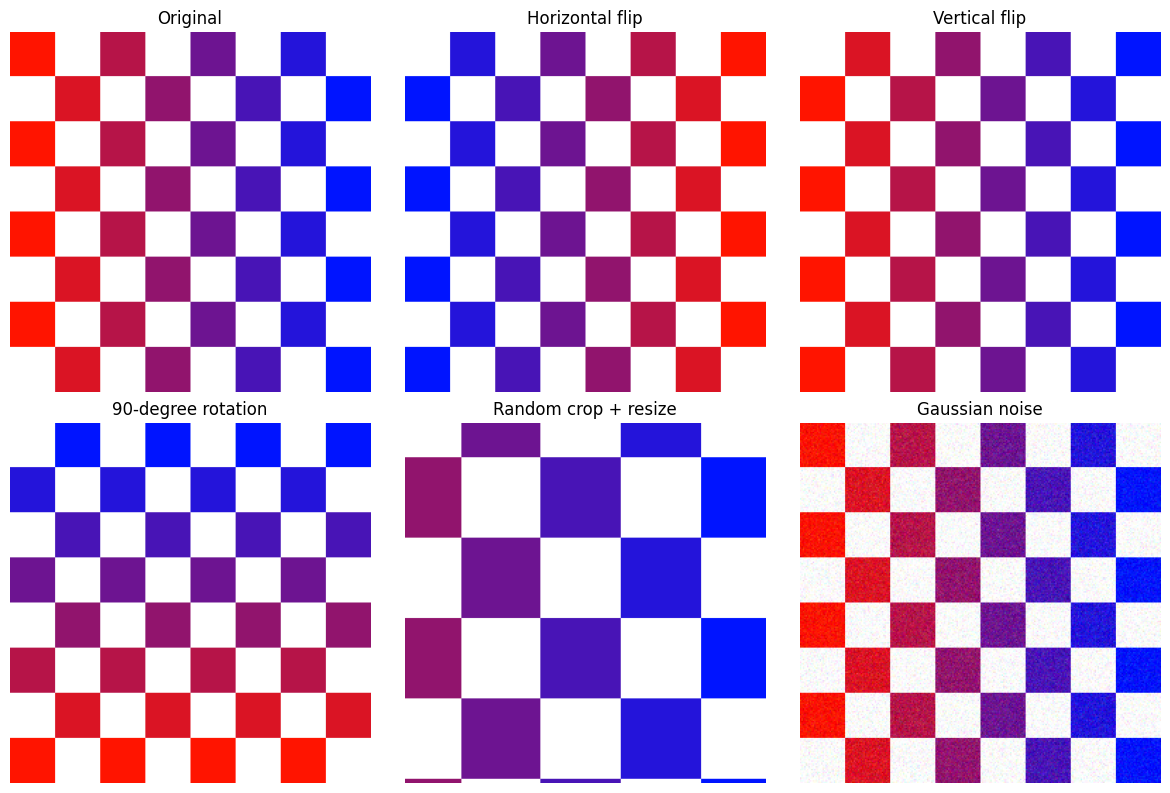

In [11]:
def make_colored_checkerboard(height=256, width=256, square=32):
    image = np.ones((height, width, 3), dtype=np.float64)
    for row in range(0, height, square):
        for col in range(0, width, square):
            grid_y = row // square
            grid_x = col // square
            if (grid_x + grid_y) % 2 == 0:
                position = col / max(width - square, 1)
                color = np.array([1.0 - position, 0.08, position])
                image[row:row + square, col:col + square] = color
    return image


def horizontal_flip(image):
    return image[:, ::-1].copy()


def vertical_flip(image):
    return image[::-1, :].copy()


def rotate_90(image, turns=1):
    return np.rot90(image, k=turns).copy()


def add_gaussian_noise(image, standard_deviation=0.06, seed=0):
    rng = np.random.default_rng(seed)
    noisy = image + rng.normal(0.0, standard_deviation, image.shape)
    return np.clip(noisy, 0.0, 1.0)


def resize_nearest(image, output_height, output_width):
    input_height, input_width = image.shape[:2]
    rows = np.floor(np.arange(output_height) * input_height / output_height).astype(int)
    cols = np.floor(np.arange(output_width) * input_width / output_width).astype(int)
    rows = np.clip(rows, 0, input_height - 1)
    cols = np.clip(cols, 0, input_width - 1)
    return image[rows[:, None], cols[None, :]]


def random_resized_crop(image, crop_height, crop_width, seed=0):
    height, width = image.shape[:2]
    if crop_height > height or crop_width > width:
        raise ValueError("crop dimensions must fit inside the image")
    rng = np.random.default_rng(seed)
    top = rng.integers(0, height - crop_height + 1)
    left = rng.integers(0, width - crop_width + 1)
    crop = image[top:top + crop_height, left:left + crop_width]
    resized = resize_nearest(crop, height, width)
    return resized, (int(top), int(left), crop_height, crop_width)


image = make_colored_checkerboard()
cropped, crop_box = random_resized_crop(image, 144, 144, seed=4)
print("Crop box (top, left, height, width):", crop_box)

examples = [
    ("Original", image),
    ("Horizontal flip", horizontal_flip(image)),
    ("Vertical flip", vertical_flip(image)),
    ("90-degree rotation", rotate_90(image)),
    ("Random crop + resize", cropped),
    ("Gaussian noise", add_gaussian_noise(image, seed=4)),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (title, example) in zip(axes.ravel(), examples):
    ax.imshow(example)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


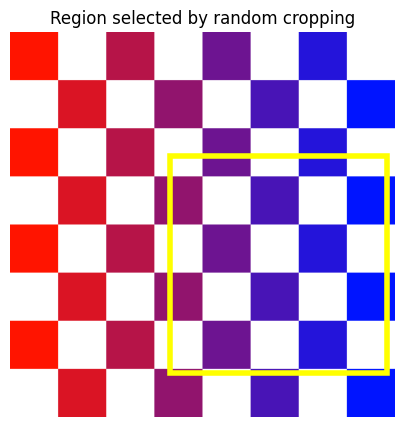

In [12]:
# Show the selected region before it is resized.
top, left, crop_height, crop_width = crop_box
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image)
rectangle = plt.Rectangle((left, top), crop_width, crop_height,
                          fill=False, edgecolor="yellow", linewidth=4)
ax.add_patch(rectangle)
ax.set_title("Region selected by random cropping")
ax.axis("off")
plt.show()


## Summary

- Training and validation curves must be interpreted together. A widening gap is a practical sign of overfitting.
- Activation functions control both the represented non-linearity and the gradients available during learning.
- L1 and L2 penalties constrain parameters differently: L1 can encourage sparsity, while L2 discourages large weights smoothly.
- Dropout perturbs hidden representations during training and discourages dependence on a fixed set of units.
- Batch normalization normalizes each feature across a batch; layer normalization normalizes the features inside each sample.
- Image augmentation is useful when it changes appearance without changing the meaning of the example. Cropping is especially effective for reducing dependence on exact position and scale.
